In [6]:
import pandas as pd
import numpy as np

In [7]:
df = pd.read_csv("train_imputed.csv")

C:\Users\SAAD IQBAL\AppData\Local\Temp\ipykernel_8360\2427471255.py:1: DtypeWarning: Columns (9: AdmissionDt, 12: DischargeDt, 13: DiagnosisGroupCode, 28: DOD) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("train_imputed.csv")


In [8]:
df.shape

(558211, 61)

In [9]:
chk = pd.read_csv("train_imputed.csv", keep_default_na=False, na_values=[""], low_memory=False)

In [10]:
df = pd.read_csv("train_imputed.csv", keep_default_na=False, na_values=[""], low_memory=False)
t_df = pd.read_csv("test_imputed.csv", keep_default_na=False, na_values=[""], low_memory=False)

In [11]:
# ===== 1) Sab date columns ko datetime banana (ClaimStartDt/ClaimEndDt abhi text ho sakte hain) =====
for x in (df, t_df):
    for c in ["ClaimStartDt", "ClaimEndDt", "AdmissionDt", "DischargeDt"]:
        x[c] = pd.to_datetime(x[c], errors="coerce")

    # ===== 2) Outpatient claims mein Admission/Discharge ki jagah claim ki dates (99.9% same hoti hain) =====
    x["AdmissionDt"] = x["AdmissionDt"].fillna(x["ClaimStartDt"])
    x["DischargeDt"] = x["DischargeDt"].fillna(x["ClaimEndDt"])

# ===== 3) DOD drop (is_deceased flag pehle se maujood hai) =====
df = df.drop(columns=["DOD"])
t_df = t_df.drop(columns=["DOD"])

# ===== 4) Check =====
print(df.isnull().sum().sum(), t_df.isnull().sum().sum())   # dono 0 aane chahiye

0 0


In [12]:
# ===== 1) Kin columns mein outliers dhoondne hain (jo columns tumhare df mein hain wahi lega) =====
OUT_COLS = [c for c in ["InscClaimAmtReimbursed", "DeductibleAmtPaid", "stay_days", "n_diag", "n_proc",
            "IPAnnualReimbursementAmt", "IPAnnualDeductibleAmt",
            "OPAnnualReimbursementAmt", "OPAnnualDeductibleAmt"] if c in df.columns]

# ===== 2) IQR method, lekin ClaimType (IP/OP) ke hisaab se alag alag =====
# Wajah: IP claims ka average ~10,088 aur OP ka ~286 hai. Ek saath nikalte to saare IP claims outlier ban jate.
def iqr_outliers(data, cols, group="ClaimType", k=1.5):
    flags = pd.DataFrame(index=data.index)
    for c in cols:
        q = data.groupby(group)[c].quantile([0.25, 0.75]).unstack()
        q1 = data[group].map(q[0.25])
        q3 = data[group].map(q[0.75])
        iqr = q3 - q1
        # iqr == 0 ho (jaise zyada tar values 0 hon) to us group mein outlier flag nahi karte
        is_out = ((data[c] < q1 - k * iqr) | (data[c] > q3 + k * iqr)) & (iqr > 0)
        flags[f"out_{c}"] = is_out.astype(int)
    return flags

flags = iqr_outliers(df, OUT_COLS)

# ===== 3) Summary: har column mein kitne outliers hain =====
summary = pd.DataFrame({"n_outliers": flags.sum(), "pct": (flags.mean() * 100).round(2)})
print(summary)

# ===== 4) Flags ko df mein jodna (delete nahi, sirf flag) =====
df["n_outlier_flags"] = flags.sum(axis=1)
df["is_outlier_any"] = (df["n_outlier_flags"] > 0).astype(int)

# ===== 5) Check: kya outlier claims mein fraud zyada hai? (agar PotentialFraud column maujood ho) =====
if "PotentialFraud" in df.columns:
    print(df.groupby("is_outlier_any")["PotentialFraud"].apply(lambda s: (s == "Yes").mean()).round(4))

                              n_outliers    pct
out_InscClaimAmtReimbursed         81341  14.57
out_DeductibleAmtPaid                  0   0.00
out_stay_days                       2792   0.50
out_n_diag                         40219   7.20
out_n_proc                           965   0.17
out_IPAnnualReimbursementAmt       75336  13.50
out_IPAnnualDeductibleAmt          17415   3.12
out_OPAnnualReimbursementAmt       37971   6.80
out_OPAnnualDeductibleAmt          36172   6.48


In [13]:
# ===== 1) Kin paison wale columns par log lagana hai (jo tumhare df mein hain wahi lega) =====
LOG_COLS = [c for c in ["InscClaimAmtReimbursed", "DeductibleAmtPaid",
            "IPAnnualReimbursementAmt", "IPAnnualDeductibleAmt",
            "OPAnnualReimbursementAmt", "OPAnnualDeductibleAmt"] if c in df.columns]

# ===== 2) Pehle ki skewness save karna (comparison ke liye) =====
before = df[LOG_COLS].skew()

# ===== 3) log1p lagana, Train aur Test dono par (naye columns _log naam se, asal columns wese hi rahenge) =====
# clip(lower=0): kuch annual reimbursement values negative hain, aur negative par log1p NaN deta hai
for x in (df, t_df):
    for c in LOG_COLS:
        x[f"{c}_log"] = np.log1p(x[c].clip(lower=0))

# ===== 4) Baad ki skewness aur comparison =====
after = df[[f"{c}_log" for c in LOG_COLS]].skew()
after.index = LOG_COLS
print(pd.DataFrame({"skew_before": before.round(2), "skew_after": after.round(2)}))

# ===== 5) Check: koi NaN nahi bana (dono 0 aane chahiye) =====
log_cols = [f"{c}_log" for c in LOG_COLS]
print(df[log_cols].isnull().sum().sum(), t_df[log_cols].isnull().sum().sum())

                          skew_before  skew_after
InscClaimAmtReimbursed           9.49        0.31
DeductibleAmtPaid                3.28        2.73
IPAnnualReimbursementAmt         3.99        0.75
IPAnnualDeductibleAmt            8.16        0.70
OPAnnualReimbursementAmt         5.52       -1.09
OPAnnualDeductibleAmt            4.36       -1.27
0 0


In [14]:
# ===== 0) Table poori dikhane ke liye display settings =====
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

# ===== 1) Kin columns ko check karna hai (jin ke _log version bane hue hain) =====
CHECK_COLS = [c for c in ["InscClaimAmtReimbursed", "DeductibleAmtPaid",
              "IPAnnualReimbursementAmt", "IPAnnualDeductibleAmt",
              "OPAnnualReimbursementAmt", "OPAnnualDeductibleAmt"]
              if c in df.columns and f"{c}_log" in df.columns]

# ===== 2) IQR outlier percentage (ClaimType ke hisaab se alag alag) =====
def iqr_out_pct(data, col, k=1.5, group="ClaimType"):
    q = data.groupby(group)[col].quantile([0.25, 0.75]).unstack()
    q1 = data[group].map(q[0.25])
    q3 = data[group].map(q[0.75])
    iqr = q3 - q1
    is_out = ((data[col] < q1 - k * iqr) | (data[col] > q3 + k * iqr)) & (iqr > 0)
    return is_out.mean() * 100

# ===== 3) Pehle (raw) aur baad (log) ka comparison table =====
rows = []
for c in CHECK_COLS:
    rows.append({
        "column": c,
        "skew_raw": round(df[c].skew(), 2),
        "skew_log": round(df[f"{c}_log"].skew(), 2),
        "outlier_%_raw": round(iqr_out_pct(df, c), 2),
        "outlier_%_log": round(iqr_out_pct(df, f"{c}_log"), 2),
        "max_raw": round(df[c].max(), 1),
        "max_log": round(df[f"{c}_log"].max(), 2),
    })
check = pd.DataFrame(rows).set_index("column")
print(check)

# ===== 4) Confirmation: outlier % aur skewness barhi nahi, kam (ya barabar) honi chahiye =====
check["outliers_kam_hue"] = check["outlier_%_log"] <= check["outlier_%_raw"]
check["skew_kam_hui"] = check["skew_log"].abs() < check["skew_raw"].abs()
print(check[["outliers_kam_hue", "skew_kam_hui"]])

                          skew_raw  skew_log  outlier_%_raw  outlier_%_log   max_raw  max_log
column                                                                                       
InscClaimAmtReimbursed        9.49      0.31          14.57           6.42  125000.0    11.74
DeductibleAmtPaid             3.28      2.73           0.00           0.00    1068.0     6.97
IPAnnualReimbursementAmt      3.99      0.75          13.50           0.13  161470.0    11.99
IPAnnualDeductibleAmt         8.16      0.70           3.12           0.13   38272.0    10.55
OPAnnualReimbursementAmt      5.52     -1.09           6.80           2.05  102960.0    11.54
OPAnnualDeductibleAmt         4.36     -1.27           6.48           2.57   13840.0     9.54
                          outliers_kam_hue  skew_kam_hui
column                                                  
InscClaimAmtReimbursed                True          True
DeductibleAmtPaid                     True          True
IPAnnualReimbursemen

In [15]:
# ===== Labels merge (Train ke df mein PotentialFraud lana) =====
if "PotentialFraud" not in df.columns:
    lab = pd.read_csv("Train-1542865627584.csv")      # apni labels file ka path/naam yahan likho
    df = df.merge(lab, on="Provider", how="left", validate="m:1")

print(df.shape)                              # column pehle se 1 zyada hone chahiye
print(df["PotentialFraud"].isna().sum())     # 0 aana chahiye
print(df["PotentialFraud"].value_counts())   # No / Yes dono dikhne chahiye

(558211, 69)
0
PotentialFraud
No     345415
Yes    212796
Name: count, dtype: int64


In [16]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, StandardScaler

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

# ===== 0) Setup: provider-level table + train/validation split (ye tests claim-level par ghalat nateeja dete hain) =====
assert "PotentialFraud" in df.columns, "df mein PotentialFraud nahi hai, pehle labels merge karo"
g = df.groupby("Provider")
prov = pd.DataFrame({
    "n_claims": g.size(),
    "n_bene": g["BeneID"].nunique(),
    "reimb_sum": g["InscClaimAmtReimbursed"].sum(),
    "reimb_mean": g["InscClaimAmtReimbursed"].mean(),
    "reimb_max": g["InscClaimAmtReimbursed"].max(),
    "reimb_std": g["InscClaimAmtReimbursed"].std().fillna(0),      # ek claim wale provider ka std 0 rakha
    "ded_mean": g["DeductibleAmtPaid"].mean(),
    "n_diag_mean": g["n_diag"].mean(),
    "n_proc_mean": g["n_proc"].mean(),
    "stay_days_mean": g["stay_days"].mean(),
    "ip_ratio": (df["ClaimType"] == "IP").groupby(df["Provider"]).mean(),
})
prov["claims_per_bene"] = prov["n_claims"] / prov["n_bene"]
prov["reimb_per_bene"] = prov["reimb_sum"] / prov["n_bene"]
prov["target"] = (g["PotentialFraud"].first() == "Yes").astype(int)

# paison/counts wale skewed columns par log1p (ratios aur chhote averages par nahi)
for c in ["n_claims", "n_bene", "reimb_sum", "reimb_mean", "reimb_max", "reimb_std", "reimb_per_bene", "ded_mean"]:
    prov[c] = np.log1p(prov[c])

FEATURES = [c for c in prov.columns if c != "target"]
train, val = train_test_split(prov, test_size=0.2, stratify=prov["target"], random_state=42)
print("Train:", train.shape, "| Validation:", val.shape, "| Fraud share (train):", round(train["target"].mean(), 4))

# ===== 1) Normalization (scaling): scaler sirf Train par fit, phir Validation par transform (leakage se bachne ke liye) =====
mm, ss = MinMaxScaler(), StandardScaler()
train_mm = pd.DataFrame(mm.fit_transform(train[FEATURES]), columns=FEATURES, index=train.index)
val_mm = pd.DataFrame(mm.transform(val[FEATURES]), columns=FEATURES, index=val.index)
train_ss = pd.DataFrame(ss.fit_transform(train[FEATURES]), columns=FEATURES, index=train.index)
print("\nMinMax (train) min/max:", train_mm.min().min().round(2), train_mm.max().max().round(2))
print("Standard (train) mean/std:", train_ss.mean().abs().max().round(4), train_ss.std().mean().round(2))

# ===== 2) Normal Distribution: skewness, kurtosis, D'Agostino K2 aur Shapiro-Wilk (p < 0.05 = normal nahi) =====
rows = []
for c in FEATURES:
    x = train[c].dropna()
    rows.append({"feature": c, "skew": round(x.skew(), 2), "kurtosis": round(x.kurt(), 2),
                 "dagostino_p": stats.normaltest(x)[1],
                 "shapiro_p": stats.shapiro(x.sample(min(len(x), 4999), random_state=42))[1]})
normality = pd.DataFrame(rows).set_index("feature")
normality["normal?"] = np.where((normality["dagostino_p"] > 0.05) & (normality["shapiro_p"] > 0.05), "Haan", "Nahi")
print("\n--- Normality ---\n", normality.round(4))

# ===== 3) Multi Co-Linearity: correlation (|r| > 0.8) aur VIF (> 10 = masla) =====
corr = train[FEATURES].corr()
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("r").reset_index())
pairs.columns = ["feature_1", "feature_2", "r"]
print("\n--- Highly correlated pairs (|r| > 0.8) ---\n", pairs[pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False).round(3))
vif = pd.Series(np.diag(np.linalg.pinv(corr.values)), index=FEATURES, name="VIF").sort_values(ascending=False)
print("\n--- VIF ---\n", vif.round(2))

# ===== 4) Independence: (a) har provider sirf ek row, (b) claim-level dependence ka saboot, (c) chi-square independence test =====
print("\nProvider duplicates (0 aana chahiye):", prov.index.duplicated().sum())
cpp = df.groupby("Provider").size()
print("Claims per provider median:", int(cpp.median()), "| max:", int(cpp.max()), "-> claims aapas mein independent nahi, isliye provider-level use kiya")
ct = pd.crosstab(train["ip_ratio"] > 0.5, train["target"])
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
print(f"Chi-square (mostly-IP vs fraud): chi2={chi2:.2f}, p={p_chi:.4g}, min expected count={expected.min():.1f} (>=5 honi chahiye)")

# ===== 5) Variance: Levene test fraud vs non-fraud (p < 0.05 = variance barabar nahi, to Welch use karo) =====
fraud, clean = train[train["target"] == 1], train[train["target"] == 0]
var_rows = []
for c in FEATURES:
    stat, p = stats.levene(fraud[c], clean[c], center="median")
    var_rows.append({"feature": c, "var_fraud": fraud[c].var(), "var_clean": clean[c].var(), "levene_p": p})
variance = pd.DataFrame(var_rows).set_index("feature")
variance["variance_barabar?"] = np.where(variance["levene_p"] > 0.05, "Haan", "Nahi")
print("\n--- Variance (Levene) ---\n", variance.round(4))

# ===== 6) Mean Comparison: Welch t-test + Mann-Whitney U, Bonferroni correction ke saath =====
mc_rows = []
for c in FEATURES:
    t_stat, p_t = stats.ttest_ind(fraud[c], clean[c], equal_var=False)
    u_stat, p_u = stats.mannwhitneyu(fraud[c], clean[c], alternative="two-sided")
    pooled = np.sqrt((fraud[c].var() + clean[c].var()) / 2)
    mc_rows.append({"feature": c, "mean_fraud": fraud[c].mean(), "mean_clean": clean[c].mean(),
                    "cohens_d": (fraud[c].mean() - clean[c].mean()) / pooled if pooled > 0 else np.nan,
                    "welch_p": p_t, "mannwhitney_p": p_u})
means = pd.DataFrame(mc_rows).set_index("feature")
alpha = 0.05 / len(FEATURES)   # Bonferroni: kayi tests ek saath chalane par threshold chhota karna parta hai
means["farq_hai?"] = np.where((means["welch_p"] < alpha) & (means["mannwhitney_p"] < alpha), "Haan", "Nahi")
print("\n--- Mean comparison (fraud vs non-fraud) ---\n", means.round(4))

Train: (4328, 14) | Validation: (1082, 14) | Fraud share (train): 0.0936

MinMax (train) min/max: 0.0 1.0
Standard (train) mean/std: 0.0 1.0

--- Normality ---
                  skew  kurtosis  dagostino_p  shapiro_p normal?
feature                                                        
n_claims         0.16     -0.37          0.0        0.0    Nahi
n_bene           0.14     -0.40          0.0        0.0    Nahi
reimb_sum       -0.65      0.73          0.0        0.0    Nahi
reimb_mean       0.29      0.53          0.0        0.0    Nahi
reimb_max       -0.66      0.94          0.0        0.0    Nahi
reimb_std       -1.40      2.88          0.0        0.0    Nahi
ded_mean         0.51     -1.21          0.0        0.0    Nahi
n_diag_mean      1.89      3.07          0.0        0.0    Nahi
n_proc_mean      3.49     16.83          0.0        0.0    Nahi
stay_days_mean   3.75     20.33          0.0        0.0    Nahi
ip_ratio         2.17      3.39          0.0        0.0    Nahi
claims_

In [17]:
from sklearn.preprocessing import PowerTransformer, StandardScaler
from scipy import stats

# ===== 0) Setup: Train/Validation pehli cell se aa rahe hain (train, val, FEATURES); "pehle" ki halat save karna =====
VIF_MAX = 10      # 10 = normal limit, zyada sakht chahiye to 5 kar do
SKEW_MAX = 1      # |skew| is se zyada ho to Yeo-Johnson lagega

def calc_vif(data):
    corr = data.corr().values
    return pd.Series(np.diag(np.linalg.pinv(corr)), index=data.columns)

before = pd.DataFrame({"skew": train[FEATURES].skew(), "kurtosis": train[FEATURES].kurt()})
vif_before_max = calc_vif(train[FEATURES]).max()

# ===== 1) Non-normality: jin features ki |skew| > SKEW_MAX unpar Yeo-Johnson (Train par fit, Val par transform) =====
skewed = [c for c in FEATURES if abs(train[c].skew()) > SKEW_MAX]
train_f, val_f = train[FEATURES].copy(), val[FEATURES].copy()
if skewed:
    pt = PowerTransformer(method="yeo-johnson", standardize=False)
    train_f[skewed] = pt.fit_transform(train[skewed])
    val_f[skewed] = pt.transform(val[skewed])
print("Yeo-Johnson in par laga:", skewed)

# ===== 2) Multicollinearity: iterative VIF removal (transform ke baad, har round mein sab se bada VIF wala hatao, sirf Train par) =====
kept = list(FEATURES)
removed = []
while len(kept) > 2:
    v = calc_vif(train_f[kept])
    if v.max() <= VIF_MAX:
        break
    worst = v.idxmax()
    removed.append((worst, round(float(v.max()), 1)))
    kept.remove(worst)
print("Hataye gaye features (feature, VIF):", removed)
print("Bache hue features:", kept)

# ===== 3) Scaling: transform aur VIF ke BAAD StandardScaler (Train par fit, Val par transform) =====
sc = StandardScaler()
train_final = pd.DataFrame(sc.fit_transform(train_f[kept]), columns=kept, index=train.index)
val_final = pd.DataFrame(sc.transform(val_f[kept]), columns=kept, index=val.index)
train_final["target"] = train["target"]
val_final["target"] = val["target"]

# ===== 4) Variance: Levene dobara chala kar dekhna (fraud vs non-fraud); Welch test barabar-variance ki shart nahi mangta =====
fr, cl = train_final[train_final["target"] == 1], train_final[train_final["target"] == 0]
lev_after = pd.Series({c: stats.levene(fr[c], cl[c], center="median")[1] for c in kept})
lev_before = pd.Series({c: stats.levene(train.loc[train["target"] == 1, c], train.loc[train["target"] == 0, c], center="median")[1] for c in kept})

# ===== 5) Verification: pehle vs baad =====
after = pd.DataFrame({"skew": train_final[kept].skew(), "kurtosis": train_final[kept].kurt()})
cmp = before.loc[kept].join(after, lsuffix="_pehle", rsuffix="_baad").round(2)
cmp["levene_p_pehle"] = lev_before.round(4)
cmp["levene_p_baad"] = lev_after.round(4)
print("\n", cmp)
print("\nFeatures:", len(FEATURES), "->", len(kept))
print("Max VIF:", round(vif_before_max, 1), "->", round(calc_vif(train_final[kept]).max(), 2))
print("Variance barabar (Levene p > 0.05):", int((lev_before > 0.05).sum()), "->", int((lev_after > 0.05).sum()), "features mein")
print("Final shapes:", train_final.shape, val_final.shape)

Yeo-Johnson in par laga: ['reimb_std', 'n_diag_mean', 'n_proc_mean', 'stay_days_mean', 'ip_ratio', 'claims_per_bene']
Hataye gaye features (feature, VIF): [('n_claims', 4760.1), ('reimb_sum', 921.4), ('reimb_mean', 199.9), ('ip_ratio', 69.1), ('reimb_max', 22.2), ('stay_days_mean', 18.7)]
Bache hue features: ['n_bene', 'reimb_std', 'ded_mean', 'n_diag_mean', 'n_proc_mean', 'claims_per_bene', 'reimb_per_bene']

                  skew_pehle  kurtosis_pehle  skew_baad  kurtosis_baad  levene_p_pehle  levene_p_baad
n_bene                 0.14           -0.40       0.14          -0.40          0.0637         0.0637
reimb_std             -1.40            2.88      -0.22           0.03          0.0000         0.0000
ded_mean               0.51           -1.21       0.51          -1.21          0.0000         0.0000
n_diag_mean            1.89            3.07      -0.17           3.91          0.0000         0.1709
n_proc_mean            3.49           16.83       1.07          -0.57          0

In [18]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import PolynomialFeatures, KBinsDiscretizer, PowerTransformer, StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold, mutual_info_classif

# ===== 1) Feature Extraction =====
CHRONIC = [x for x in df.columns if x.startswith("ChronicCond_")]
need = ["Provider", "BeneID", "ClaimType", "ClaimStartDt", "ClaimEndDt", "DOB", "InscClaimAmtReimbursed",
        "DeductibleAmtPaid", "AttendingPhysician", "State", "ClmDiagnosisCode_1", "n_diag", "n_proc",
        "stay_days", "PotentialFraud"] + CHRONIC
c = df[need].copy()
for col in ["ClaimStartDt", "ClaimEndDt", "DOB"]:
    c[col] = pd.to_datetime(c[col], errors="coerce")
c["claim_days"] = (c["ClaimEndDt"] - c["ClaimStartDt"]).dt.days + 1
c["age"] = (c["ClaimStartDt"] - c["DOB"]).dt.days / 365.25
c["chronic_count"] = (c[CHRONIC] == 1).sum(axis=1)
c["is_ip"] = (c["ClaimType"] == "IP").astype(int)
c["amt_per_day"] = c["InscClaimAmtReimbursed"] / c["claim_days"].clip(lower=1)
c["round_amount"] = ((c["InscClaimAmtReimbursed"] % 100 == 0) & (c["InscClaimAmtReimbursed"] > 0)).astype(int)
c["dup_claim"] = c.duplicated(["Provider", "BeneID", "ClaimStartDt"], keep=False).astype(int)
c["no_attending"] = (c["AttendingPhysician"].isna() | (c["AttendingPhysician"] == "Missing")).astype(int)

# ===== 2) Date & Time Feature Extraction =====
c["is_weekend"] = (c["ClaimStartDt"].dt.dayofweek >= 5).astype(int)
c["year_month"] = c["ClaimStartDt"].dt.to_period("M").astype(str)

# ===== 3) Aggregating Features =====
g = c.groupby("Provider")
prov = pd.DataFrame({
    "n_claims": g.size(),
    "n_bene": g["BeneID"].nunique(),
    "reimb_sum": g["InscClaimAmtReimbursed"].sum(),
    "reimb_mean": g["InscClaimAmtReimbursed"].mean(),
    "reimb_max": g["InscClaimAmtReimbursed"].max(),
    "reimb_std": g["InscClaimAmtReimbursed"].std().fillna(0),
    "ded_mean": g["DeductibleAmtPaid"].mean(),
    "n_diag_mean": g["n_diag"].mean(),
    "n_proc_mean": g["n_proc"].mean(),
    "stay_days_mean": g["stay_days"].mean(),
    "claim_days_mean": g["claim_days"].mean(),
    "age_mean": g["age"].mean(),
    "chronic_mean": g["chronic_count"].mean(),
    "amt_per_day_mean": g["amt_per_day"].mean(),
    "ip_ratio": g["is_ip"].mean(),
    "weekend_ratio": g["is_weekend"].mean(),
    "round_ratio": g["round_amount"].mean(),
    "dup_ratio": g["dup_claim"].mean(),
    "no_attending_ratio": g["no_attending"].mean(),
    "n_active_months": g["year_month"].nunique(),
    "active_days": (g["ClaimStartDt"].max() - g["ClaimStartDt"].min()).dt.days + 1,
    "n_attending": g["AttendingPhysician"].nunique(),
    "n_states": g["State"].nunique(),
    "top_state": g["State"].agg(lambda s: s.mode().iloc[0]).astype(str),
})
prov["claims_per_bene"] = prov["n_claims"] / prov["n_bene"]
prov["reimb_per_bene"] = prov["reimb_sum"] / prov["n_bene"]
prov["claims_per_active_day"] = prov["n_claims"] / prov["active_days"]
prov["target"] = (g["PotentialFraud"].first() == "Yes").astype(int)
tr_idx, va_idx = train_test_split(prov.index, test_size=0.2, stratify=prov["target"], random_state=42)
Xtr, Xva = prov.loc[tr_idx].copy(), prov.loc[va_idx].copy()
print("Provider table:", prov.shape, "| Train:", Xtr.shape, "| Val:", Xva.shape)

# ===== 4) Text Feature Extraction =====
dx = c.loc[c["ClmDiagnosisCode_1"].notna() & (c["ClmDiagnosisCode_1"] != "None")]
docs = dx.groupby("Provider")["ClmDiagnosisCode_1"].apply(lambda s: " ".join(s.astype(str))).reindex(prov.index).fillna("")
tfidf = TfidfVectorizer(max_features=15, token_pattern=r"\S+", lowercase=False).fit(docs.loc[Xtr.index])
tf_cols = ["tfidf_" + t for t in tfidf.get_feature_names_out()]
for X in (Xtr, Xva):
    T = tfidf.transform(docs.loc[X.index]).toarray()
    for j, name in enumerate(tf_cols):
        X[name] = T[:, j]

# ===== 5) Feature Encoding =====
top5 = Xtr["top_state"].value_counts().head(5).index.tolist()
freq = Xtr["top_state"].value_counts(normalize=True)
cats = top5 + ["Other"]
for X in (Xtr, Xva):
    X["state_freq"] = X["top_state"].map(freq).fillna(0)
    grp = pd.Series(pd.Categorical(np.where(X["top_state"].isin(top5), X["top_state"], "Other"), categories=cats), index=X.index)
    dummies = pd.get_dummies(grp, prefix="state").astype(int)
    for col in dummies.columns:
        X[col] = dummies[col]
    X.drop(columns="top_state", inplace=True)

# ===== 6) Interaction Features =====
for X in (Xtr, Xva):
    X["ip_x_reimb"] = X["ip_ratio"] * X["reimb_mean"]
    X["diag_x_proc"] = X["n_diag_mean"] * X["n_proc_mean"]
    X["chronic_x_age"] = X["chronic_mean"] * X["age_mean"]
    X["dup_x_claims"] = X["dup_ratio"] * X["n_claims"]

# ===== 7) Polynomial Features =====
POLY = ["reimb_mean", "n_diag_mean", "claims_per_bene"]
poly = PolynomialFeatures(degree=2, include_bias=False).fit(Xtr[POLY])
all_names = poly.get_feature_names_out(POLY)
new_idx = [i for i, n in enumerate(all_names) if n not in POLY]
new_names = ["poly_" + all_names[i].replace("^2", "_sq").replace(" ", "_x_") for i in new_idx]
for X in (Xtr, Xva):
    P = poly.transform(X[POLY])
    for i, name in zip(new_idx, new_names):
        X[name] = P[:, i]

# ===== 8) Feature Binning / Discretization =====
BIN = ["reimb_mean", "age_mean", "claims_per_bene"]
kb = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy="quantile").fit(Xtr[BIN])
for X in (Xtr, Xva):
    B = kb.transform(X[BIN])
    for j, col in enumerate(BIN):
        X[col + "_bin"] = B[:, j]

# ===== 9) Handling Skewed Features =====
cont = [col for col in Xtr.columns if col != "target" and not col.startswith(("state_", "tfidf_")) or col == "state_freq"]
cont = [col for col in cont if not col.endswith("_bin") and Xtr[col].nunique() > 10]
skewed = [col for col in cont if abs(Xtr[col].skew()) > 1]
pt = PowerTransformer(method="yeo-johnson", standardize=False).fit(Xtr[skewed])
Xtr[skewed] = pt.transform(Xtr[skewed])
Xva[skewed] = pt.transform(Xva[skewed])
print("Skewed features transform hue:", len(skewed), "| max |skew| baad mein:", round(Xtr[skewed].skew().abs().max(), 2))

# ===== 10) Feature Scaling =====
SC = [col for col in Xtr.columns if col != "target" and (not col.startswith("state_") or col == "state_freq")]
sc = StandardScaler().fit(Xtr[SC])
Xtr[SC] = sc.transform(Xtr[SC])
Xva[SC] = sc.transform(Xva[SC])

# ===== 11) Dimensionality Reduction =====
FEAT = [col for col in Xtr.columns if col != "target"]
pca = PCA(n_components=0.95, random_state=42).fit(Xtr[FEAT])
pc_names = [f"pc{i + 1}" for i in range(pca.n_components_)]
Xtr_pca = pd.DataFrame(pca.transform(Xtr[FEAT]), index=Xtr.index, columns=pc_names)
Xva_pca = pd.DataFrame(pca.transform(Xva[FEAT]), index=Xva.index, columns=pc_names)
print("PCA:", len(FEAT), "features ->", pca.n_components_, "components (95% variance)")

# ===== 12) Feature Selection =====
y = Xtr["target"]
vt = VarianceThreshold(0.01).fit(Xtr[FEAT])
f1 = [col for col, keep in zip(FEAT, vt.get_support()) if keep]
corr = Xtr[f1].corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
f2 = [col for col in f1 if not (upper[col] > 0.95).any()]
mi = pd.Series(mutual_info_classif(Xtr[f2], y, random_state=42), index=f2).sort_values(ascending=False)
SELECTED = mi.head(20).index.tolist()
Xtr_sel, Xva_sel = Xtr[SELECTED + ["target"]], Xva[SELECTED + ["target"]]
print("Selection:", len(FEAT), "->", len(f1), "(variance) ->", len(f2), "(correlation) ->", len(SELECTED), "(mutual info)")
print(mi.head(10).round(3))
print("Final:", Xtr_sel.shape, Xva_sel.shape)

Provider table: (5410, 28) | Train: (4328, 28) | Val: (1082, 28)
Skewed features transform hue: 32 | max |skew| baad mein: 2.74
PCA: 61 features -> 27 components (95% variance)
Selection: 61 -> 61 (variance) -> 49 (correlation) -> 20 (mutual info)
reimb_sum                             0.141
reimb_max                             0.105
n_proc_mean                           0.083
ded_mean                              0.076
reimb_std                             0.073
n_claims                              0.065
n_diag_mean                           0.063
stay_days_mean                        0.062
poly_n_diag_mean_x_claims_per_bene    0.061
reimb_mean                            0.059
dtype: float64
Final: (4328, 21) (1082, 21)


Accuracy : 0.926
Precision: 0.573
Recall   : 0.812
F1       : 0.672
ROC-AUC  : 0.96
PR-AUC   : 0.773


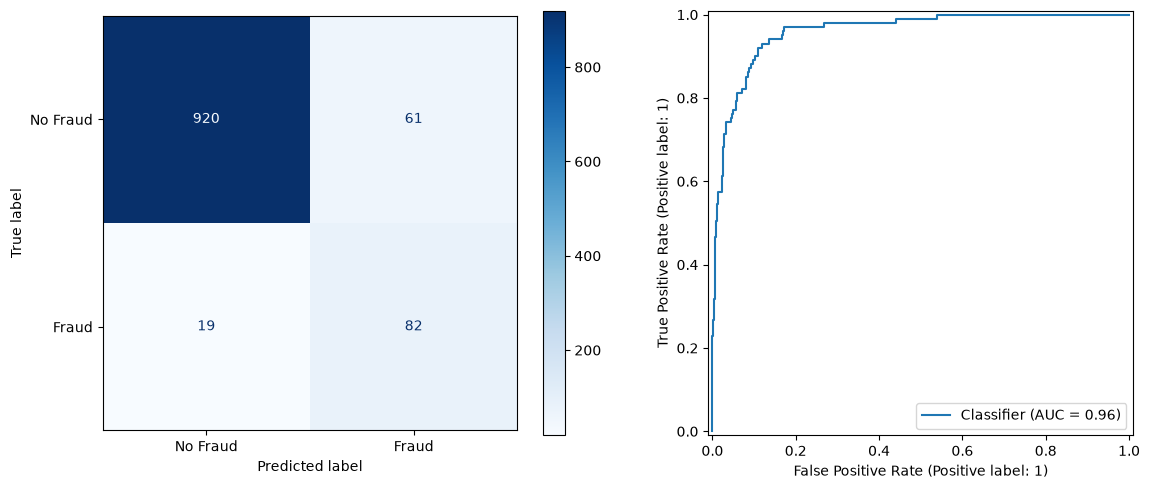

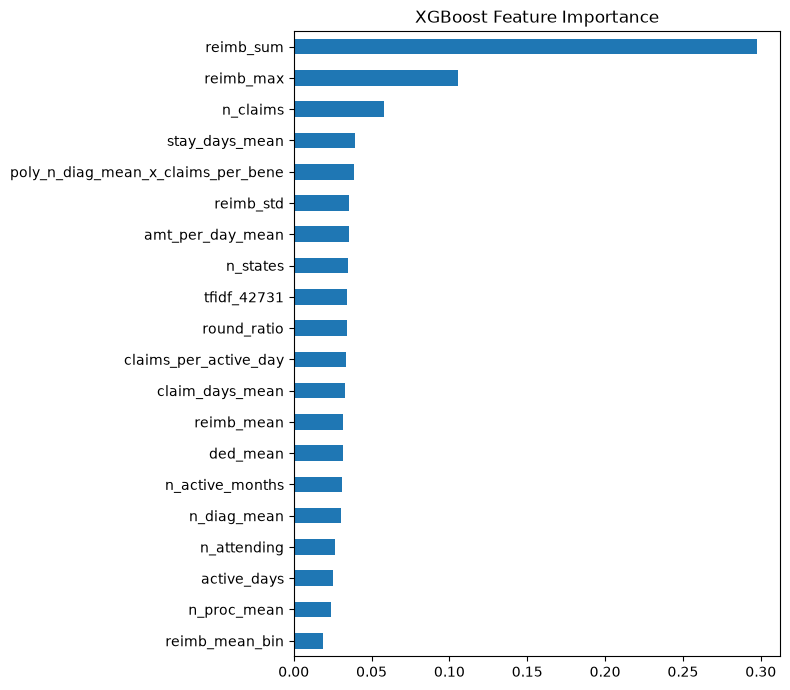

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay

# Feature Scaling
Xt, yt = Xtr_sel.drop(columns="target"), Xtr_sel["target"]
Xv, yv = Xva_sel.drop(columns="target"), Xva_sel["target"]
sc = StandardScaler()
Xt_s = pd.DataFrame(sc.fit_transform(Xt), columns=Xt.columns, index=Xt.index)
Xv_s = pd.DataFrame(sc.transform(Xv), columns=Xv.columns, index=Xv.index)

# Model Initialization
model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(yt == 0).sum() / (yt == 1).sum(),
    eval_metric="logloss",
    random_state=42,
)

# Model Training
model.fit(Xt_s, yt)

# Model Prediction
y_prob = model.predict_proba(Xv_s)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

# Model Evaluation
print("Accuracy :", round(accuracy_score(yv, y_pred), 3))
print("Precision:", round(precision_score(yv, y_pred), 3))
print("Recall   :", round(recall_score(yv, y_pred), 3))
print("F1       :", round(f1_score(yv, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(yv, y_prob), 3))
print("PR-AUC   :", round(average_precision_score(yv, y_prob), 3))

# Result Visualization (Confusion Matrix, ROC Curve)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(yv, y_pred), display_labels=["No Fraud", "Fraud"]).plot(ax=ax[0], cmap="Blues")
RocCurveDisplay.from_predictions(yv, y_prob, ax=ax[1])
plt.tight_layout()
plt.show()

# Feature Importance Analysis
imp = pd.Series(model.feature_importances_, index=Xt.columns).sort_values()
imp.plot(kind="barh", figsize=(8, 7), title="XGBoost Feature Importance")
plt.tight_layout()
plt.show()

{'subsample': 1.0, 'scale_pos_weight': 1, 'reg_lambda': 5, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.8} 0.686
Best threshold: 0.296
Accuracy : 0.935
Precision: 0.637
Recall   : 0.713
F1       : 0.673
ROC-AUC  : 0.962
PR-AUC   : 0.767


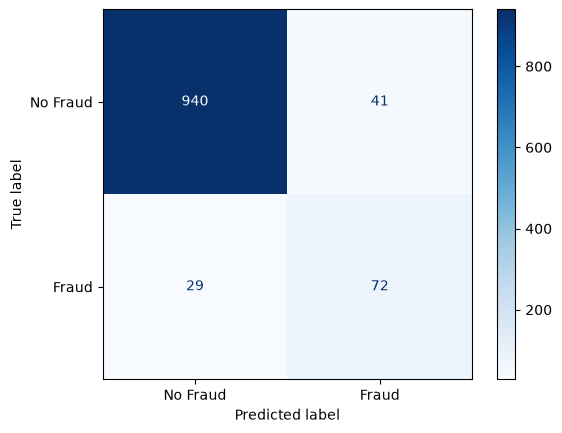

In [20]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve

# Hyperparameter Tuning (PR-AUC par, sirf train data)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
params = {
    "n_estimators": [200, 300, 500, 800],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.3],
    "reg_lambda": [1, 3, 5],
    "scale_pos_weight": [1, 3, 5, (yt == 0).sum() / (yt == 1).sum()],
}
search = RandomizedSearchCV(
    XGBClassifier(eval_metric="logloss", random_state=42),
    params, n_iter=40, scoring="average_precision", cv=skf, random_state=42, n_jobs=-1,
)
search.fit(Xt_s, yt)
best = search.best_estimator_
print(search.best_params_, round(search.best_score_, 3))

# Threshold Tuning (train ke out-of-fold predictions par, validation use nahi hota)
oof = cross_val_predict(best, Xt_s, yt, cv=skf, method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(yt, oof)
f1s = 2 * p * r / (p + r + 1e-9)
thr = t[f1s[:-1].argmax()]
print("Best threshold:", round(thr, 3))

# Final Evaluation (validation par sirf ek baar)
best.fit(Xt_s, yt)
y_prob = best.predict_proba(Xv_s)[:, 1]
y_pred = (y_prob >= thr).astype(int)
print("Accuracy :", round(accuracy_score(yv, y_pred), 3))
print("Precision:", round(precision_score(yv, y_pred), 3))
print("Recall   :", round(recall_score(yv, y_pred), 3))
print("F1       :", round(f1_score(yv, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(yv, y_prob), 3))
print("PR-AUC   :", round(average_precision_score(yv, y_prob), 3))
ConfusionMatrixDisplay(confusion_matrix(yv, y_pred), display_labels=["No Fraud", "Fraud"]).plot(cmap="Blues")
plt.show()

              CV PR-AUC  CV PR-AUC std  CV ROC-AUC  CV F1  Val Accuracy  Val Precision  Val Recall  Val F1  Val ROC-AUC  Val PR-AUC
Model                                                                                                                              
XGBoost           0.689          0.028       0.935  0.585         0.945          0.769       0.594   0.670        0.962       0.767
LogReg            0.687          0.027       0.939  0.537         0.866          0.408       0.970   0.575        0.962       0.759
HistGB            0.682          0.019       0.932  0.605         0.936          0.640       0.723   0.679        0.945       0.742
AdaBoost          0.676          0.028       0.930  0.578         0.943          0.753       0.574   0.652        0.950       0.743
GradBoost         0.669          0.038       0.933  0.584         0.944          0.770       0.564   0.651        0.958       0.771
RandomForest      0.667          0.022       0.933  0.541         0.947     

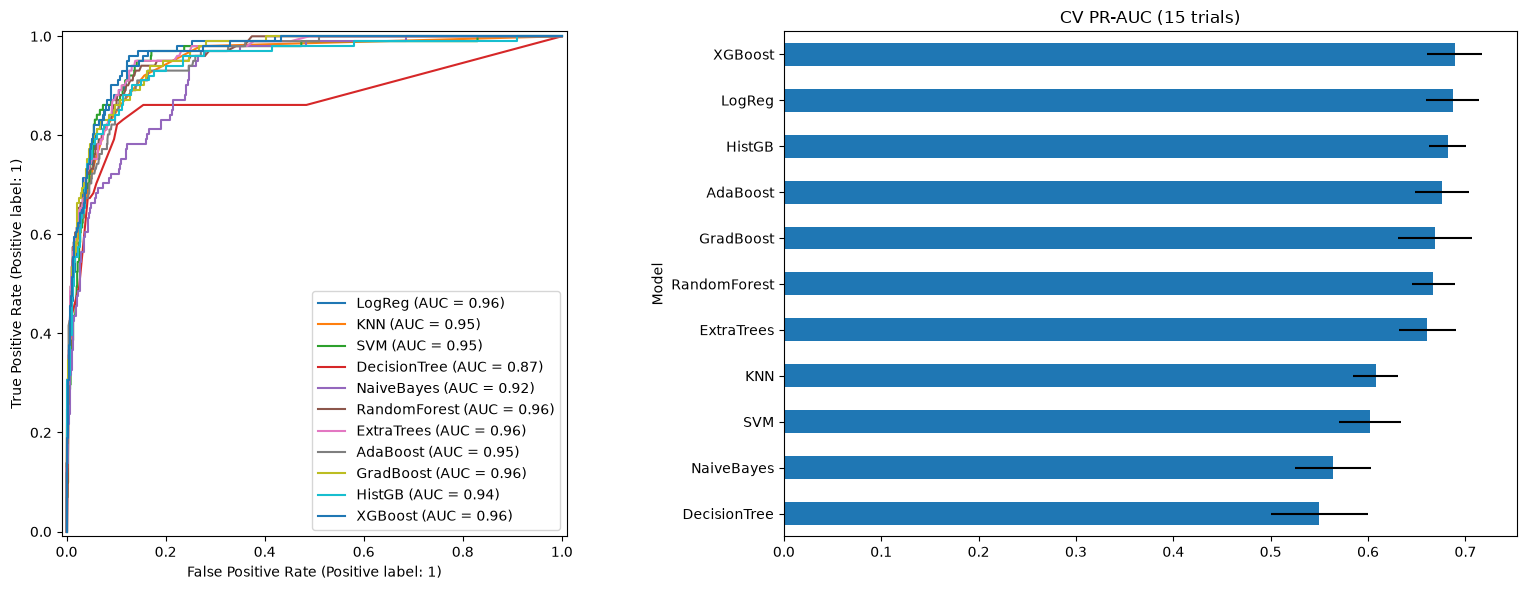

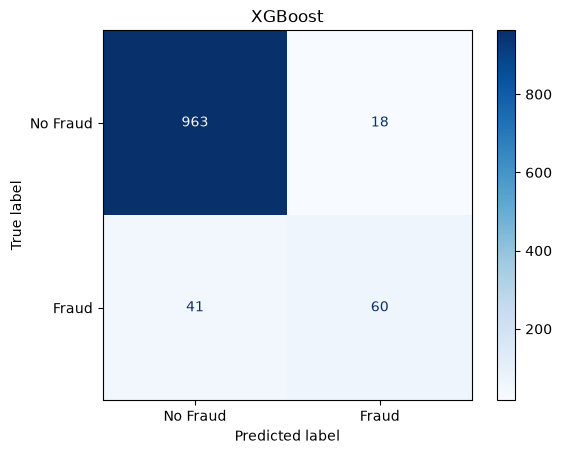

In [21]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier, AdaBoostClassifier

# Models Initialization
models = {
    "LogReg": LogisticRegression(class_weight="balanced", max_iter=2000),
    "KNN": KNeighborsClassifier(n_neighbors=15),
    "SVM": SVC(probability=True, class_weight="balanced", random_state=42),
    "DecisionTree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "NaiveBayes": GaussianNB(),
    "RandomForest": RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", random_state=42),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=500, class_weight="balanced_subsample", random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=300, random_state=42),
    "GradBoost": GradientBoostingClassifier(random_state=42),
    "HistGB": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    "XGBoost": XGBClassifier(subsample=1.0, scale_pos_weight=1, reg_lambda=5, n_estimators=200, min_child_weight=3,
                             max_depth=6, learning_rate=0.05, gamma=0, colsample_bytree=0.8,
                             eval_metric="logloss", random_state=42),
}

# Trials Setup (5-fold x 3 repeats = 15 trials per model)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision"}

# Training, Cross-Validation Trials aur Validation Prediction
rows, probs = [], {}
for name, m in models.items():
    cvr = cross_validate(m, Xt_s, yt, cv=cv, scoring=scoring, n_jobs=-1)
    prob = m.fit(Xt_s, yt).predict_proba(Xv_s)[:, 1]
    pred = (prob >= 0.5).astype(int)
    probs[name] = prob
    rows.append({
        "Model": name,
        "CV PR-AUC": cvr["test_pr_auc"].mean(),
        "CV PR-AUC std": cvr["test_pr_auc"].std(),
        "CV ROC-AUC": cvr["test_roc_auc"].mean(),
        "CV F1": cvr["test_f1"].mean(),
        "Val Accuracy": accuracy_score(yv, pred),
        "Val Precision": precision_score(yv, pred, zero_division=0),
        "Val Recall": recall_score(yv, pred),
        "Val F1": f1_score(yv, pred),
        "Val ROC-AUC": roc_auc_score(yv, prob),
        "Val PR-AUC": average_precision_score(yv, prob),
    })

# Results Comparison Table
results = pd.DataFrame(rows).set_index("Model").sort_values("CV PR-AUC", ascending=False).round(3)
print(results)

# Result Visualization (ROC Curves aur CV PR-AUC)
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for name, prob in probs.items():
    RocCurveDisplay.from_predictions(yv, prob, name=name, ax=ax[0])
r = results.sort_values("CV PR-AUC")
r["CV PR-AUC"].plot(kind="barh", xerr=r["CV PR-AUC std"], ax=ax[1], title="CV PR-AUC (15 trials)")
plt.tight_layout()
plt.show()

# Best Model ka Confusion Matrix
best_name = results.index[0]
best_pred = (probs[best_name] >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(yv, best_pred), display_labels=["No Fraud", "Fraud"]).plot(cmap="Blues")
plt.title(best_name)
plt.show()

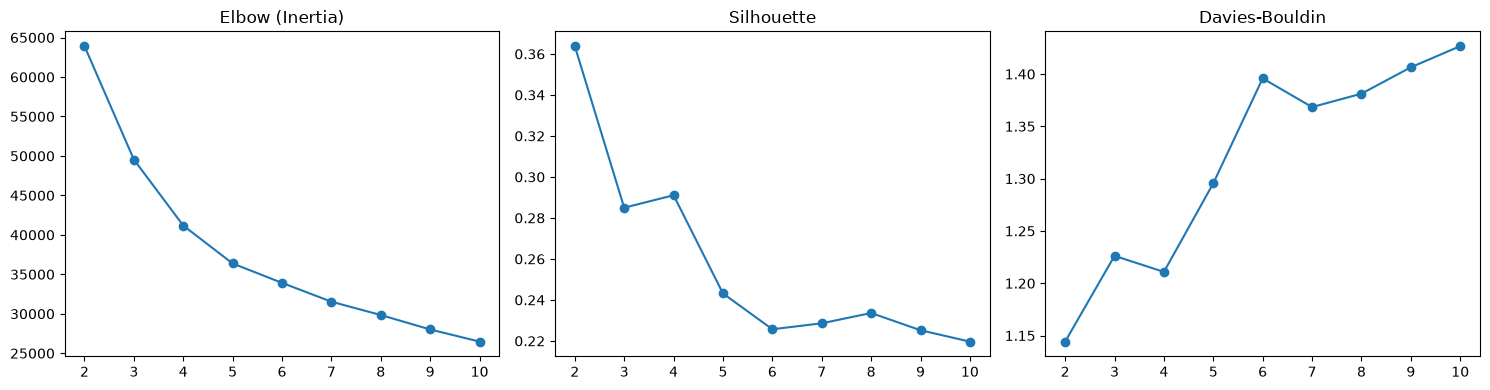

PCA components: 9 | Best K: 2


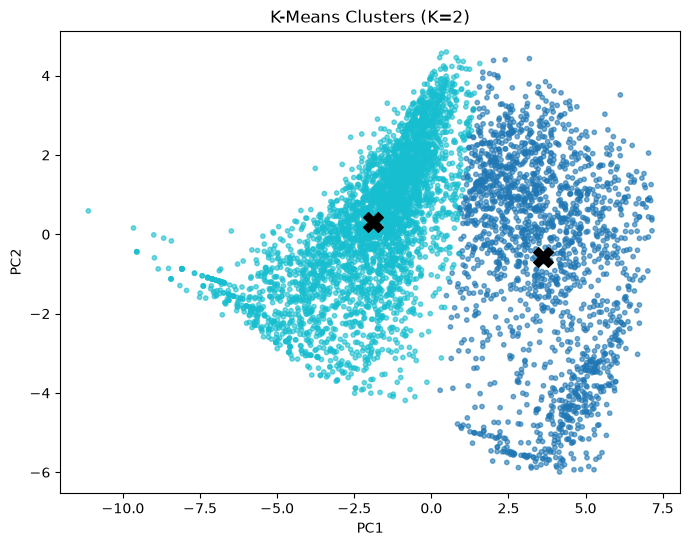

Silhouette       : 0.364
Davies-Bouldin   : 1.144
Calinski-Harabasz: 3292.2
cluster                                    0         1
reimb_sum                              0.880    -0.460
reimb_max                              1.100    -0.580
n_proc_mean                            1.210    -0.640
ded_mean                               1.200    -0.630
reimb_std                              1.030    -0.540
n_claims                               0.180    -0.090
n_diag_mean                            0.870    -0.460
stay_days_mean                         1.280    -0.670
poly_n_diag_mean_x_claims_per_bene     0.660    -0.350
reimb_mean                             1.100    -0.580
round_ratio                            0.700    -0.370
claims_per_active_day                  0.130    -0.070
claim_days_mean                        0.710    -0.380
reimb_mean_bin                         1.110    -0.580
amt_per_day_mean                       0.940    -0.490
active_days                            0.170

In [22]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Data Preparation
data = pd.concat([Xtr_sel, Xva_sel])
y_true = data["target"]
X = data.drop(columns="target")

# Feature Scaling
Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)

# Optimal Number of Clusters Determination (PCA ke baad)
pca = PCA(n_components=0.95, random_state=42)
Xp = pca.fit_transform(Xs)
ks = range(2, 11)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xp)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xp, km.labels_))
    dbi.append(davies_bouldin_score(Xp, km.labels_))
best_k = list(ks)[sil.index(max(sil))]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (Inertia)")
ax[1].plot(ks, sil, marker="o"); ax[1].set_title("Silhouette")
ax[2].plot(ks, dbi, marker="o"); ax[2].set_title("Davies-Bouldin")
plt.tight_layout()
plt.show()
print("PCA components:", pca.n_components_, "| Best K:", best_k)

# Model Applying (K-Means with PCA)
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xp)

# Cluster Label Assign
data["cluster"] = kmeans.labels_

# Cluster Visualization
plt.figure(figsize=(8, 6))
plt.scatter(Xp[:, 0], Xp[:, 1], c=kmeans.labels_, cmap="tab10", s=10, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="black", marker="X", s=200)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"K-Means Clusters (K={best_k})")
plt.show()

# Cluster Evaluation
print("Silhouette       :", round(silhouette_score(Xp, kmeans.labels_), 3))
print("Davies-Bouldin   :", round(davies_bouldin_score(Xp, kmeans.labels_), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(Xp, kmeans.labels_), 1))

# Cluster Interpretation
profile = Xs.groupby(data["cluster"]).mean().round(2)
profile["size"] = data["cluster"].value_counts().sort_index()
profile["fraud_rate"] = y_true.groupby(data["cluster"]).mean().round(3)
print(profile.T)
for c in profile.index:
    top = profile.loc[c, X.columns].sort_values(key=abs, ascending=False).head(3)
    print(f"Cluster {c} ({int(profile.loc[c, 'size'])} providers, fraud {profile.loc[c, 'fraud_rate']}):", dict(top))

DBSCAN eps: 1.861 | min_samples: 18
           Clusters  Noise %  Silhouette  Davies-Bouldin  Calinski-Harabasz  Max Fraud Rate  Fraud Gap  Smallest Cluster %
Algorithm                                                                                                                 
Average           2      0.0       0.492           0.447             11.773           0.094      0.094               0.037
HDBSCAN           3     65.6       0.489           0.679           1511.280           0.206      0.170               7.734
KMeans            2      0.0       0.364           1.144           3292.226           0.229      0.207              34.473
Spectral          2      0.0       0.361           1.149           3262.773           0.221      0.194              34.621
Ward              2      0.0       0.347           1.182           3190.961           0.216      0.195              37.320
Birch             2      0.0       0.347           1.185           3184.472           0.218      0.199 

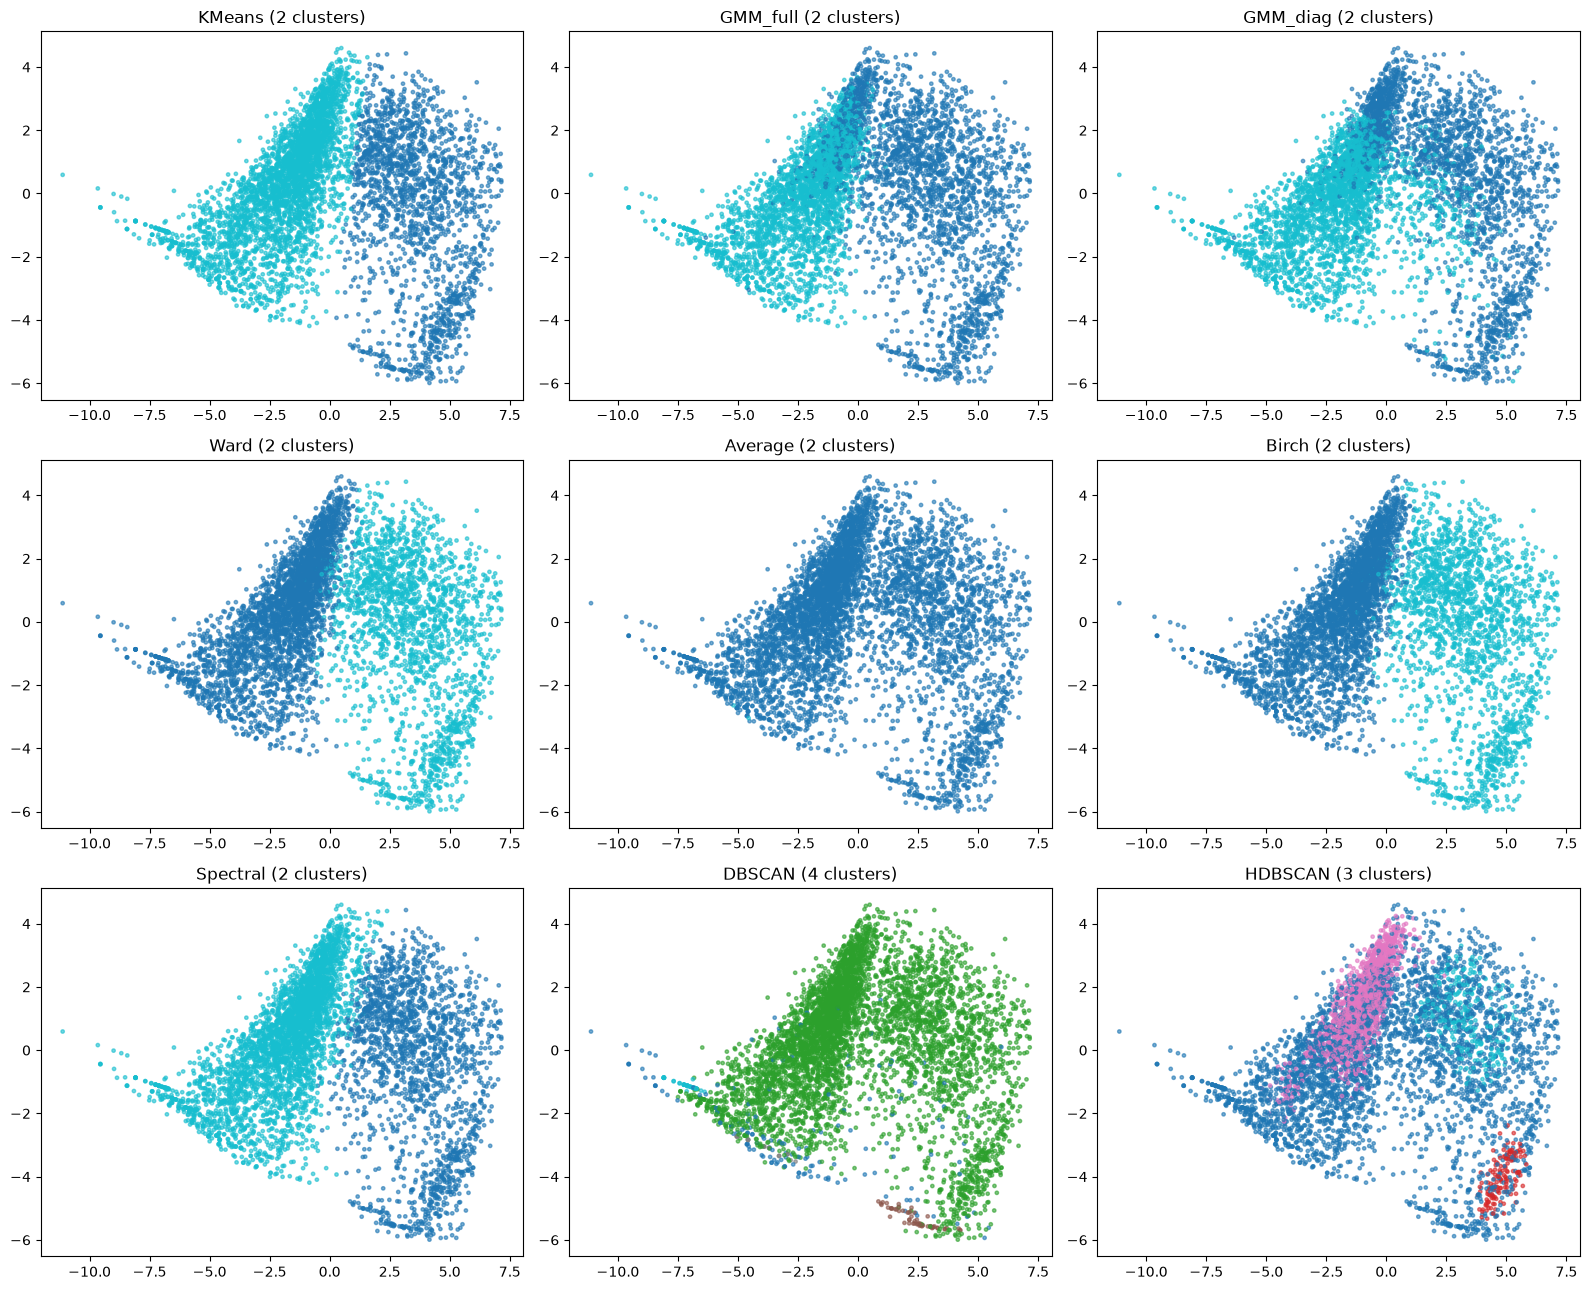

Best algorithm: Average
cluster                                    0     1
reimb_sum                              0.000 -2.99
reimb_max                              0.000 -3.12
n_proc_mean                           -0.000  0.68
ded_mean                              -0.000  1.55
reimb_std                              0.000 -2.29
n_claims                               0.000 -1.93
n_diag_mean                           -0.000  2.33
stay_days_mean                        -0.000  1.81
poly_n_diag_mean_x_claims_per_bene    -0.000  1.94
reimb_mean                             0.000 -5.08
round_ratio                            0.000 -2.24
claims_per_active_day                 -0.000  1.74
claim_days_mean                       -0.000  1.51
reimb_mean_bin                         0.000 -1.41
amt_per_day_mean                       0.000 -4.94
active_days                            0.000 -2.58
tfidf_42731                            0.000 -0.44
n_attending                            0.000 -1.41
n_activ

In [23]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering, Birch, DBSCAN, HDBSCAN, SpectralClustering
from sklearn.neighbors import NearestNeighbors

# DBSCAN ke liye eps Selection (k-distance method)
ms = 2 * Xp.shape[1]
kdist = np.sort(NearestNeighbors(n_neighbors=ms).fit(Xp).kneighbors(Xp)[0][:, -1])
eps = np.percentile(kdist, 90)
print("DBSCAN eps:", round(eps, 3), "| min_samples:", ms)

# Algorithms Initialization
algos = {
    "KMeans": KMeans(n_clusters=best_k, n_init=10, random_state=42),
    "GMM_full": GaussianMixture(n_components=best_k, covariance_type="full", n_init=5, random_state=42),
    "GMM_diag": GaussianMixture(n_components=best_k, covariance_type="diag", n_init=5, random_state=42),
    "Ward": AgglomerativeClustering(n_clusters=best_k, linkage="ward"),
    "Average": AgglomerativeClustering(n_clusters=best_k, linkage="average"),
    "Birch": Birch(n_clusters=best_k),
    "Spectral": SpectralClustering(n_clusters=best_k, affinity="nearest_neighbors", n_neighbors=15, random_state=42),
    "DBSCAN": DBSCAN(eps=eps, min_samples=ms),
    "HDBSCAN": HDBSCAN(min_cluster_size=50),
}

# Fitting, Labels aur Evaluation
rows, all_labels = [], {}
for name, algo in algos.items():
    labels = algo.fit_predict(Xp)
    all_labels[name] = labels
    mask = labels != -1
    k_found = len(set(labels[mask]))
    row = {"Algorithm": name, "Clusters": k_found, "Noise %": round((~mask).mean() * 100, 1)}
    if k_found >= 2:
        fr = pd.Series(y_true.values[mask]).groupby(labels[mask]).mean()
        row.update({
            "Silhouette": silhouette_score(Xp[mask], labels[mask]),
            "Davies-Bouldin": davies_bouldin_score(Xp[mask], labels[mask]),
            "Calinski-Harabasz": calinski_harabasz_score(Xp[mask], labels[mask]),
            "Max Fraud Rate": fr.max(),
            "Fraud Gap": fr.max() - fr.min(),
            "Smallest Cluster %": pd.Series(labels[mask]).value_counts(normalize=True).min() * 100,
        })
    rows.append(row)

# Results Comparison Table
res = pd.DataFrame(rows).set_index("Algorithm").sort_values("Silhouette", ascending=False).round(3)
print(res)

# Cluster Visualization (PC1 vs PC2)
fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, (name, labels) in zip(axes.flat, all_labels.items()):
    ax.scatter(Xp[:, 0], Xp[:, 1], c=labels, cmap="tab10", s=6, alpha=0.6)
    ax.set_title(f"{name} ({len(set(labels) - {-1})} clusters)")
plt.tight_layout()
plt.show()

# Best Algorithm ka Cluster Interpretation
best_algo = res.index[0]
data["cluster"] = all_labels[best_algo]
profile = Xs.groupby(data["cluster"]).mean().round(2)
profile["size"] = data["cluster"].value_counts().sort_index()
profile["fraud_rate"] = y_true.groupby(data["cluster"]).mean().round(3)
print("Best algorithm:", best_algo)
print(profile.T)

Silhouette       : 0.364
Davies-Bouldin   : 1.144
Calinski-Harabasz: 3292.2
         size  size_%  fraud_count  fraud_rate  fraud_captured_%
cluster                                                         
0        1865    34.5          427       0.229              84.4
1        3545    65.5           79       0.022              15.6
cluster                                0     1
reimb_sum                           0.88 -0.46
reimb_max                           1.10 -0.58
n_proc_mean                         1.21 -0.64
ded_mean                            1.20 -0.63
reimb_std                           1.03 -0.54
n_claims                            0.18 -0.09
n_diag_mean                         0.87 -0.46
stay_days_mean                      1.28 -0.67
poly_n_diag_mean_x_claims_per_bene  0.66 -0.35
reimb_mean                          1.10 -0.58
round_ratio                         0.70 -0.37
claims_per_active_day               0.13 -0.07
claim_days_mean                     0.71 -0.38
reimb_

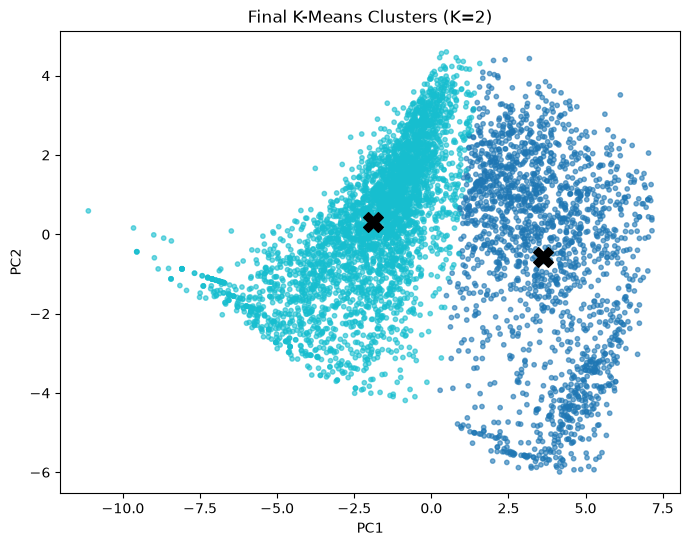

In [24]:
# Final K-Means Cluster Assign (data["cluster"] pehle Average ke labels se overwrite ho chuka hai, isliye dobara set karna zaroori hai)
final = KMeans(n_clusters=2, n_init=10, random_state=42).fit(Xp)
data["cluster"] = final.labels_

# Cluster Evaluation
print("Silhouette       :", round(silhouette_score(Xp, final.labels_), 3))
print("Davies-Bouldin   :", round(davies_bouldin_score(Xp, final.labels_), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(Xp, final.labels_), 1))

# Cluster Size aur Fraud Rate
summary = pd.DataFrame({
    "size": data["cluster"].value_counts().sort_index(),
    "size_%": (data["cluster"].value_counts(normalize=True).sort_index() * 100).round(1),
    "fraud_count": y_true.groupby(data["cluster"]).sum(),
    "fraud_rate": y_true.groupby(data["cluster"]).mean().round(3),
})
summary["fraud_captured_%"] = (summary["fraud_count"] / y_true.sum() * 100).round(1)
print(summary)

# Cluster Profile (z-score means)
profile = Xs.groupby(data["cluster"]).mean().round(2)
print(profile.T)

# Cluster Visualization
plt.figure(figsize=(8, 6))
plt.scatter(Xp[:, 0], Xp[:, 1], c=final.labels_, cmap="tab10", s=10, alpha=0.6)
plt.scatter(final.cluster_centers_[:, 0], final.cluster_centers_[:, 1], c="black", marker="X", s=200)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("Final K-Means Clusters (K=2)")
plt.show()

In [25]:
# Original CSV Columns (claim-level, chk raw file hai)
print("Raw CSV columns        :", chk.shape[1])

# df Columns (cleaning, flags, log aur label ke baad)
print("df columns (abhi)      :", df.shape[1])

# Provider-Level Features (Feature Engineering ka aggregation step, target ke baghair)
print("Provider table features:", prov.shape[1] - 1)

# Features Selection se pehle (encoding, interaction, poly, binning ke baad)
print("FEAT (selection se pehle):", len(FEAT))

# Final Selected Features
print("SELECTED               :", len(SELECTED))

Raw CSV columns        : 61
df columns (abhi)      : 69
Provider table features: 27
FEAT (selection se pehle): 61
SELECTED               : 20


In [26]:
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest

pipe = Pipeline([
    ("sel", SelectKBest(mutual_info_classif, k=20)),
    ("xgb", XGBClassifier(subsample=1.0, scale_pos_weight=1, reg_lambda=5, n_estimators=200, min_child_weight=3,
                          max_depth=6, learning_rate=0.05, gamma=0, colsample_bytree=0.8,
                          eval_metric="logloss", random_state=42)),
])
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)
cvr = cross_validate(pipe, Xtr[f2], Xtr["target"], cv=cv, scoring={"pr_auc": "average_precision", "recall": "recall"}, n_jobs=-1)
print("CV PR-AUC:", cvr["test_pr_auc"].mean().round(3), "+-", cvr["test_pr_auc"].std().round(3))
print("CV Recall:", cvr["test_recall"].mean().round(3))

pipe.fit(Xtr[f2], Xtr["target"])
pv = pipe.predict_proba(Xva[f2])[:, 1]
yv_ = Xva["target"].values
rng = np.random.default_rng(42)
bs = []
for _ in range(1000):
    i = rng.integers(0, len(yv_), len(yv_))
    if yv_[i].sum() > 0:
        bs.append(average_precision_score(yv_[i], pv[i]))
print("Val PR-AUC 95% CI:", np.percentile(bs, [2.5, 97.5]).round(3))

data = pd.concat([Xtr[f2], Xva[f2]])
y_true = pd.concat([Xtr["target"], Xva["target"]])
X = data.copy()

CV PR-AUC: 0.682 +- 0.023
CV Recall: 0.499
Val PR-AUC 95% CI: [0.686 0.837]


Best threshold: 0.252
Accuracy : 0.938
Precision: 0.644
Recall   : 0.752
F1       : 0.694
ROC-AUC  : 0.964
PR-AUC   : 0.775


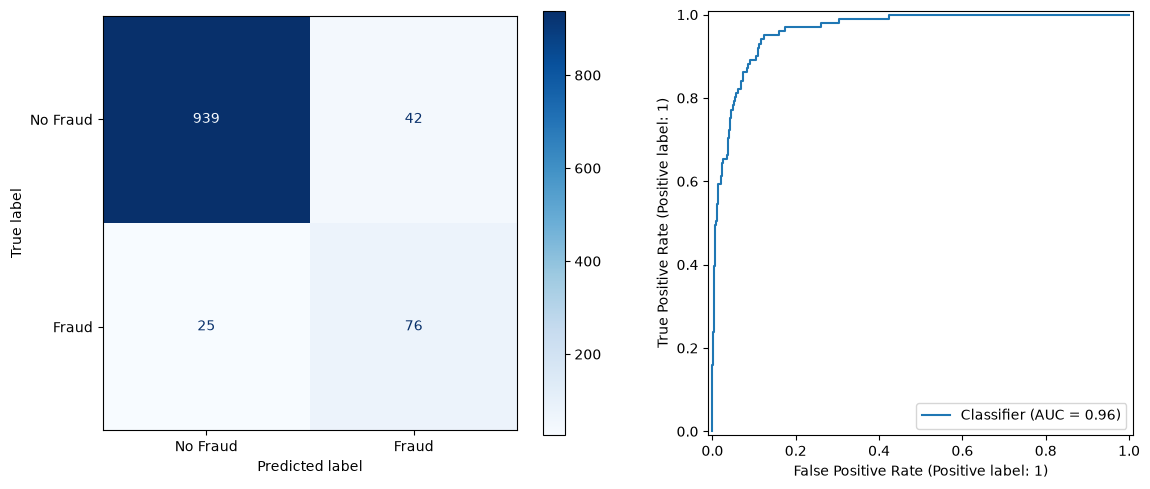

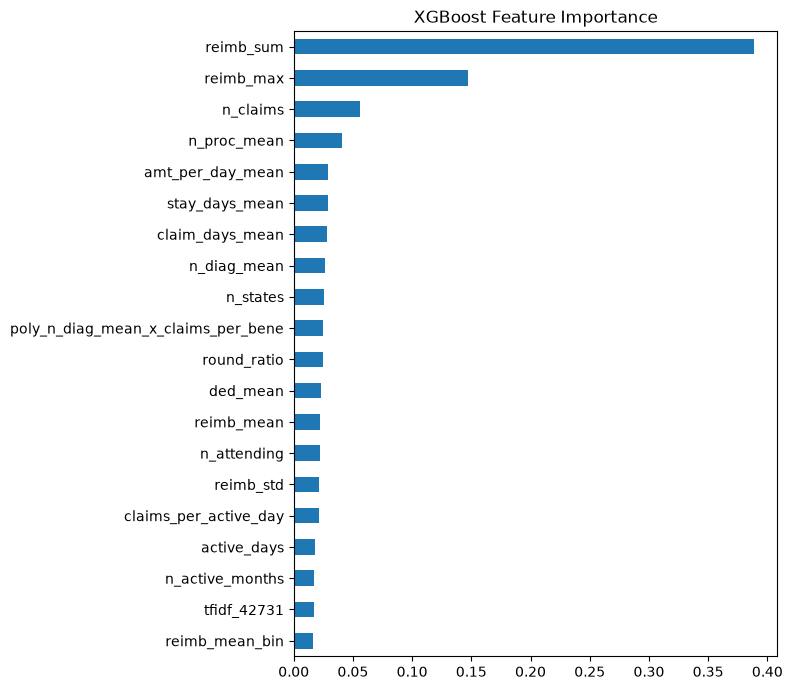

In [27]:
# Data Preparation
Xt, yt = Xtr[f2], Xtr["target"]
Xv, yv = Xva[f2], Xva["target"]

# Model Initialization (selection pipeline ke andar)
pipe = Pipeline([
    ("sel", SelectKBest(lambda a, b: mutual_info_classif(a, b, random_state=42), k=20)),
    ("xgb", XGBClassifier(subsample=1.0, scale_pos_weight=1, reg_lambda=5, n_estimators=200, min_child_weight=3,
                          max_depth=6, learning_rate=0.05, gamma=0, colsample_bytree=0.8,
                          eval_metric="logloss", random_state=42)),
])

# Threshold Tuning (train ke out-of-fold predictions par)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof = cross_val_predict(pipe, Xt, yt, cv=skf, method="predict_proba")[:, 1]
p, r, t = precision_recall_curve(yt, oof)
thr = t[(2 * p * r / (p + r + 1e-9))[:-1].argmax()]
print("Best threshold:", round(thr, 3))

# Model Training
pipe.fit(Xt, yt)

# Model Prediction
y_prob = pipe.predict_proba(Xv)[:, 1]
y_pred = (y_prob >= thr).astype(int)

# Model Evaluation
print("Accuracy :", round(accuracy_score(yv, y_pred), 3))
print("Precision:", round(precision_score(yv, y_pred), 3))
print("Recall   :", round(recall_score(yv, y_pred), 3))
print("F1       :", round(f1_score(yv, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(yv, y_prob), 3))
print("PR-AUC   :", round(average_precision_score(yv, y_prob), 3))

# Result Visualization (Confusion Matrix, ROC Curve)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(confusion_matrix(yv, y_pred), display_labels=["No Fraud", "Fraud"]).plot(ax=ax[0], cmap="Blues")
RocCurveDisplay.from_predictions(yv, y_prob, ax=ax[1])
plt.tight_layout()
plt.show()

# Feature Importance Analysis
sel_cols = Xt.columns[pipe.named_steps["sel"].get_support()]
pd.Series(pipe.named_steps["xgb"].feature_importances_, index=sel_cols).sort_values().plot(kind="barh", figsize=(8, 7), title="XGBoost Feature Importance")
plt.tight_layout()
plt.show()

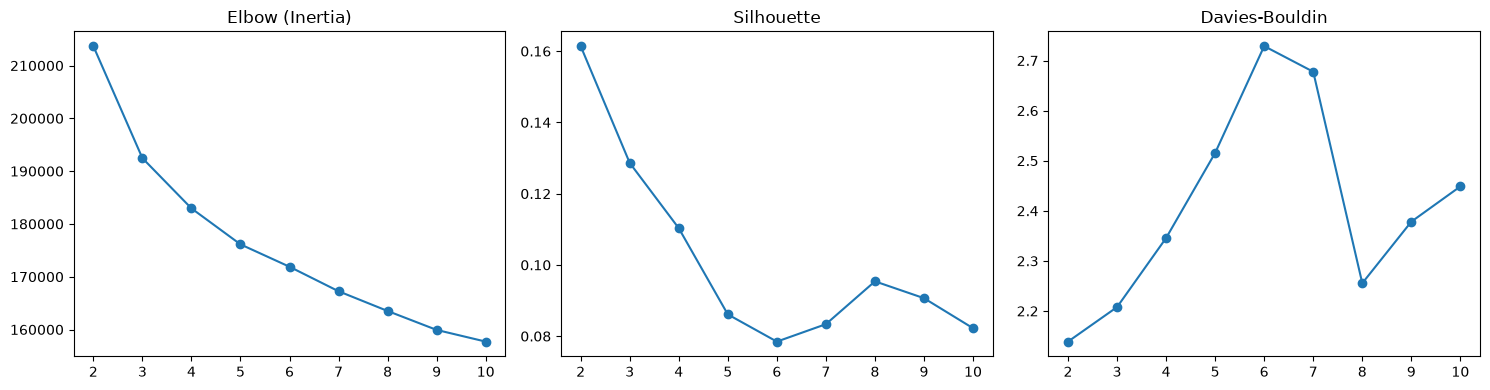

Features: 49 | PCA components: 31 | Best K: 2


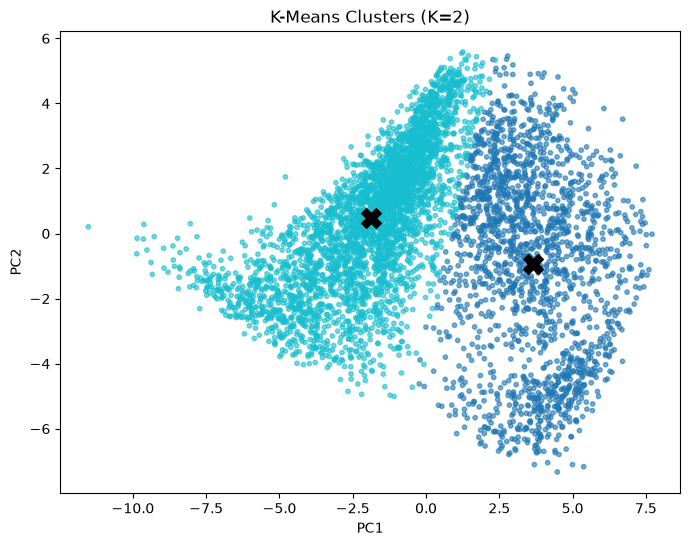

Silhouette       : 0.161
Davies-Bouldin   : 2.139
Calinski-Harabasz: 1018.7
         size  fraud_rate  fraud_captured_%
cluster                                    
0        1844       0.229              83.4
1        3566       0.024              16.6
cluster                                0     1
n_claims                            0.17 -0.09
reimb_sum                           0.88 -0.46
reimb_mean                          1.11 -0.58
reimb_max                           1.11 -0.57
reimb_std                           1.04 -0.54
ded_mean                            1.21 -0.62
n_diag_mean                         0.89 -0.46
n_proc_mean                         1.22 -0.63
stay_days_mean                      1.30 -0.67
claim_days_mean                     0.72 -0.37
age_mean                            0.02 -0.01
chronic_mean                        0.38 -0.20
amt_per_day_mean                    0.95 -0.49
weekend_ratio                       0.00 -0.00
round_ratio                         0.71 -0

In [28]:
# Data Preparation
data = pd.concat([Xtr, Xva])
y_true = data["target"]
X = data[f2]

# Feature Scaling
Xs = pd.DataFrame(StandardScaler().fit_transform(X), columns=X.columns, index=X.index)

# PCA
pca = PCA(n_components=0.95, random_state=42)
Xp = pca.fit_transform(Xs)

# Optimal Number of Clusters Determination
ks = range(2, 11)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xp)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(Xp, km.labels_))
    dbi.append(davies_bouldin_score(Xp, km.labels_))
best_k = list(ks)[sil.index(max(sil))]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(ks, inertia, marker="o"); ax[0].set_title("Elbow (Inertia)")
ax[1].plot(ks, sil, marker="o"); ax[1].set_title("Silhouette")
ax[2].plot(ks, dbi, marker="o"); ax[2].set_title("Davies-Bouldin")
plt.tight_layout()
plt.show()
print("Features:", X.shape[1], "| PCA components:", pca.n_components_, "| Best K:", best_k)

# Model Applying (K-Means with PCA)
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42).fit(Xp)

# Cluster Label Assign
data["cluster"] = kmeans.labels_

# Cluster Visualization
plt.figure(figsize=(8, 6))
plt.scatter(Xp[:, 0], Xp[:, 1], c=kmeans.labels_, cmap="tab10", s=10, alpha=0.6)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c="black", marker="X", s=200)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title(f"K-Means Clusters (K={best_k})")
plt.show()

# Cluster Evaluation
print("Silhouette       :", round(silhouette_score(Xp, kmeans.labels_), 3))
print("Davies-Bouldin   :", round(davies_bouldin_score(Xp, kmeans.labels_), 3))
print("Calinski-Harabasz:", round(calinski_harabasz_score(Xp, kmeans.labels_), 1))

# Cluster Interpretation
summary = pd.DataFrame({
    "size": data["cluster"].value_counts().sort_index(),
    "fraud_rate": y_true.groupby(data["cluster"]).mean().round(3),
    "fraud_captured_%": (y_true.groupby(data["cluster"]).sum() / y_true.sum() * 100).round(1),
})
print(summary)
print(Xs.groupby(data["cluster"]).mean().round(2).T)

In [29]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pipe = ImbPipeline([
    ("sel", SelectKBest(lambda a, b: mutual_info_classif(a, b, random_state=42), k=20)),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(scale_pos_weight=1, n_estimators=200, max_depth=6, learning_rate=0.05,
                          eval_metric="logloss", random_state=42)),
])
cvr = cross_validate(pipe, Xtr[f2], Xtr["target"], cv=cv, scoring={"pr_auc": "average_precision", "recall": "recall"}, n_jobs=-1)
print(cvr["test_pr_auc"].mean().round(3), cvr["test_recall"].mean().round(3))

0.655 0.673
